# Shor's Nine-Qubit Code: Protecting One Qubit from Any Single Error

**Colin Casey, 2026.** SymPy for the algebra, Qiskit for the circuit, Lean 4 for the proofs.

| Section | Question it answers |
|---|---|
| 1. The idea in plain English | Why spread one qubit over nine? |
| 2. The codewords and their checks | What are $\lvert 0_L\rangle$, $\lvert 1_L\rangle$ and the eight stabilizers? |
| 3. The circuit | How do you encode, detect and correct in Qiskit? |
| 4. Every single error is corrected | Does it really fix all 27 single-qubit Pauli errors? |
| 5. The exact logical error rate | What is $p_L(p)$ under depolarizing noise, exactly? |
| 6. Reading the slope | Why does a slope of 2 on a log-log plot mean the code works? |
| 7. Proofs in Lean 4 | Can a proof assistant certify the checks, the logicals and the error counts? |

Kernel: **py312**. Lean: `leanprover/lean4:v4.34.0-rc2`.

In [1]:
import itertools, subprocess, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, partial_trace, state_fidelity
sp.init_printing(use_latex='mathjax')
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=OI), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

---
## 1. The idea in plain English

A qubit can go wrong in two basic ways: a **bit flip** ($X$, swaps $|0\rangle$ and $|1\rangle$) or a **phase flip** ($Z$, flips the sign of $|1\rangle$). A $Y$ error is both at once. Any small, messy error on one qubit is a combination of $I$, $X$, $Y$ and $Z$, so a code that fixes those four on every qubit fixes **every** single-qubit error.

Shor's 1995 idea was to **nest** two simple codes:
- **Inside**, each group of three qubits uses majority voting against bit flips: $|0\rangle \to |000\rangle$, $|1\rangle \to |111\rangle$.
- **Outside**, three such groups use the same trick against phase flips, by comparing the *signs* of the groups.

The code never measures the data itself, which would destroy the superposition. It measures **parities** ("do these two qubits agree?"), which point at the damaged qubit without revealing what the qubit holds.

---
## 2. The codewords and their checks

$$|0_L\rangle = \frac{(|000\rangle + |111\rangle)^{\otimes 3}}{2\sqrt2}, \qquad |1_L\rangle = \frac{(|000\rangle - |111\rangle)^{\otimes 3}}{2\sqrt2}$$

**Stabilizers** are the parity checks; both codewords are $+1$ eigenvectors of all eight:
- six $Z$-type checks, two per group: $Z_0Z_1,\ Z_1Z_2,\ Z_3Z_4,\ Z_4Z_5,\ Z_6Z_7,\ Z_7Z_8$;
- two $X$-type checks across groups: $X_0X_1X_2X_3X_4X_5$ and $X_3X_4X_5X_6X_7X_8$.

**Logical operators** act on the encoded qubit: $\bar X = Z^{\otimes 9}$ swaps the codewords and $\bar Z = X^{\otimes 9}$ flips the sign of $|1_L\rangle$. Below, SymPy builds the 512-entry codewords exactly and checks all of this.

In [2]:
NQ = 9
def pauli_on(label):            # label like 'ZZIIIIIII', qubit 0 = leftmost character here
    P = {'I': sp.eye(2), 'X': sp.Matrix([[0, 1], [1, 0]]), 'Z': sp.Matrix([[1, 0], [0, -1]]), 'Y': sp.Matrix([[0, -sp.I], [sp.I, 0]])}
    return sp.kronecker_product(*[P[c] for c in label])

ket = lambda bits: sp.Matrix([1 if j == int(bits, 2) else 0 for j in range(2**NQ)])
plus_block = lambda s: [('000', 1), ('111', s)]
def codeword(sign):
    v = sp.zeros(2**NQ, 1)
    for (b1, s1), (b2, s2), (b3, s3) in itertools.product(plus_block(sign), repeat=3):
        v += s1*s2*s3*ket(b1 + b2 + b3)
    return v/(2*sp.sqrt(2))
zero_L, one_L = codeword(+1), codeword(-1)
print('norms:', sp.simplify((zero_L.T*zero_L)[0]), sp.simplify((one_L.T*one_L)[0]), '  overlap:', (zero_L.T*one_L)[0])

STAB = ['ZZIIIIIII', 'IZZIIIIII', 'IIIZZIIII', 'IIIIZZIII', 'IIIIIIZZI', 'IIIIIIIZZ', 'XXXXXXIII', 'IIIXXXXXX']
for s in STAB:
    S = pauli_on(s)
    ok = (S*zero_L == zero_L) and (S*one_L == one_L)
    print(f'{s}:  fixes |0_L> and |1_L>: {ok}')
Xbar, Zbar = pauli_on('ZZZZZZZZZ'), pauli_on('XXXXXXXXX')
print('Xbar |0_L> = |1_L>:', Xbar*zero_L == one_L, '   Zbar |1_L> = -|1_L>:', Zbar*one_L == -one_L, '   Zbar |0_L> = |0_L>:', Zbar*zero_L == zero_L)

norms: 1 1   overlap: 0


ZZIIIIIII:  fixes |0_L> and |1_L>: True


IZZIIIIII:  fixes |0_L> and |1_L>: True


IIIZZIIII:  fixes |0_L> and |1_L>: True


IIIIZZIII:  fixes |0_L> and |1_L>: True


IIIIIIZZI:  fixes |0_L> and |1_L>: True


IIIIIIIZZ:  fixes |0_L> and |1_L>: True


XXXXXXIII:  fixes |0_L> and |1_L>: True


IIIXXXXXX:  fixes |0_L> and |1_L>: True


Xbar |0_L> = |1_L>: True    Zbar |1_L> = -|1_L>: True    Zbar |0_L> = |0_L>: True


---
## 3. The circuit

Qubits 0–8 hold the data. Ancillas 9–14 record the six bit-flip parities (two per group), ancillas 15–16 the two phase parities. Corrections are applied with **controlled gates** instead of mid-circuit measurements: the *deferred-measurement principle* says this is equivalent, and it keeps the whole cycle one unitary that a statevector can simulate exactly. 17 qubits is $2^{17} = 131{,}072$ amplitudes: easy as a statevector, impossible as a density matrix ($2^{34}$ entries).

In [3]:
N = 17
BLOCKS = ((0, 1, 2), (3, 4, 5), (6, 7, 8))

def encoder():
    qc = QuantumCircuit(N, name='encode')
    qc.cx(0, 3); qc.cx(0, 6); qc.h([0, 3, 6])                 # outer: phase-flip code across groups
    for a, b, c in BLOCKS:
        qc.cx(a, b); qc.cx(a, c)                              # inner: bit-flip code in each group
    return qc

def bit_flip_round(qc, qubits, anc):
    q0, q1, q2 = qubits
    qc.cx(q0, anc[0]); qc.cx(q1, anc[0]); qc.cx(q1, anc[1]); qc.cx(q2, anc[1])
    qc.mcx(list(anc), q0, ctrl_state='01')                    # syndrome (1,0): flip q0
    qc.mcx(list(anc), q1, ctrl_state='11')                    # syndrome (1,1): flip q1
    qc.mcx(list(anc), q2, ctrl_state='10')                    # syndrome (0,1): flip q2

def corrector():
    qc = QuantumCircuit(N, name='correct')
    for g, blk in enumerate(BLOCKS):
        bit_flip_round(qc, blk, (9 + 2*g, 10 + 2*g))
    for a, b, c in BLOCKS:
        qc.cx(a, c); qc.cx(a, b)                              # each group -> its leader
    qc.h([0, 3, 6])                                           # sign flips -> bit flips on the leaders
    bit_flip_round(qc, (0, 3, 6), (15, 16))
    qc.cx(0, 6); qc.cx(0, 3)                                  # leaders -> qubit 0
    return qc

def cycle(errors=None):
    qc = encoder(); qc.barrier(label='errors')
    for qb, P in (errors or {}).items():
        getattr(qc, P.lower())(qb)
    qc.barrier()
    return qc.compose(corrector())

def run_cycle(psi, errors=None):
    sv = Statevector.from_label('0'*(N - 1)).tensor(psi).evolve(cycle(errors))
    return partial_trace(sv, list(range(1, N)))

qc_demo = cycle({4: 'Y'})
print('gates:', dict(qc_demo.count_ops()), '  depth:', qc_demo.depth())

gates: {'cx': 32, 'h': 6, 'ccx_o1': 4, 'ccx': 4, 'ccx_o2': 4, 'barrier': 2, 'y': 1}   depth: 25


---
## 4. Every single error is corrected

Six test states (the eigenstates of $X$, $Y$, $Z$) × 27 single-qubit errors ($X$, $Y$ or $Z$ on any of nine qubits), plus no error: 168 full 17-qubit simulations. Every output fidelity should be 1.

In [4]:
STATES = {'0': [1, 0], '1': [0, 1], '+': [1, 1], '-': [1, -1], '+i': [1, 1j], '-i': [1, -1j]}
STATES = {k: Statevector(np.array(v)/np.linalg.norm(v)) for k, v in STATES.items()}
t0 = time.perf_counter()
worst = 1.0
for errs in [None] + [{q: P} for q in range(9) for P in 'XYZ']:
    for s in STATES.values():
        worst = min(worst, state_fidelity(run_cycle(s, errs), s))
print(f'168 runs in {time.perf_counter() - t0:.1f} s; worst fidelity = {worst:.12f}')

168 runs in 24.4 s; worst fidelity = 1.000000000000


---
## 5. The exact logical error rate

**Depolarizing noise:** each data qubit independently suffers $X$, $Y$ or $Z$ with probability $p/3$ each. Two errors can fool the checks, so the code sometimes fails. To get $p_L(p)$ **exactly**, a classical "Pauli-frame" model of this decoder predicts the logical error for any error pattern:
- in each group, two or more $X$'s get "corrected" into $XXX$, which ends up as a $Z$ on the leader;
- an odd number of $Z$'s in a group flips that group's sign; two or more flipped groups fool the outer check.

The model is first checked against the Qiskit circuit on random multi-qubit errors, then run on **all $4^9 = 262{,}144$** patterns:
$$p_L(p) = \sum_{k=0}^{9} N_k \left(\frac p3\right)^k (1-p)^{9-k}, \qquad N_k = \#\{\text{weight-}k\text{ patterns that fail}\}$$

In [5]:
def predict_logical(errors):
    x = np.zeros(9, int); z = np.zeros(9, int)
    for qb, P in errors.items():
        x[qb] ^= P in 'XY'; z[qb] ^= P in 'ZY'
    resid = [int(x[list(b)].sum() >= 2) for b in BLOCKS]
    zpar = [int(z[list(b)].sum() % 2) for b in BLOCKS]
    return int(sum(zpar) >= 2), int(sum(resid) % 2)          # (logical X?, logical Z?)

def apply_logical(psi, lx, lz):
    v = np.asarray(psi.data).copy()
    if lz: v = v*np.array([1, -1])
    if lx: v = v[::-1]
    return Statevector(v)

rng = np.random.default_rng(7); agree = 0; trials = 120
for _ in range(trials):
    w = rng.integers(2, 6)
    errs = {int(q): 'XYZ'[rng.integers(3)] for q in rng.choice(9, w, replace=False)}
    s = list(STATES.values())[rng.integers(6)]
    agree += state_fidelity(run_cycle(s, errs), apply_logical(s, *predict_logical(errs))) > 1 - 1e-9
print(f'Pauli-frame model matches the Qiskit circuit on {agree}/{trials} random weight-2..5 errors')

Nk = []
for k in range(10):
    fails = sum(any(predict_logical(dict(zip(qs, ps))))
                for qs in itertools.combinations(range(9), k) for ps in itertools.product('XYZ', repeat=k))
    Nk.append(fails)
total = [sp.binomial(9, k)*3**k for k in range(10)]
print('weight k :', list(range(10)))
print('failing  :', Nk)
print('total    :', [int(t) for t in total])

Pauli-frame model matches the Qiskit circuit on 120/120 random weight-2..5 errors


weight k : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
failing  : [0, 0, 144, 1464, 7704, 23760, 46656, 57816, 43416, 15648]
total    : [1, 27, 324, 2268, 10206, 30618, 61236, 78732, 59049, 19683]


In [6]:
p = sp.symbols('p', positive=True)
pL = sp.expand(sum(Nk[k]*(p/3)**k*(1 - p)**(9 - k) for k in range(10)))
display(sp.Eq(sp.Symbol('p_L(p)'), pL))
lead = sp.series(pL, p, 0, 3).removeO()
display(sp.Eq(sp.Symbol(r'p_L \approx'), lead))
roots = sorted(float(sp.re(r_)) for r_ in sp.Poly(sp.expand((pL - p)/p), p).nroots() if abs(sp.im(r_)) < 1e-12 and 0 < sp.re(r_) < 1)
print('real roots of p_L = p in (0, 1):', [round(r_, 4) for r_ in roots])
p_star = roots[0]
print(f'break-even with a bare qubit: p* = {p_star:.4f}  -> the code helps for p < {p_star:.3f}  (rough estimate 1/16 = 0.0625 from p_L ≈ 16 p²)')
print('(p = 3/4 is also a root: there the noise scrambles any qubit completely, so coded and bare fail equally often)')

                  9         8          7        6         5        4        3  ↪
           16384⋅p    4096⋅p    12800⋅p    896⋅p    1120⋅p    952⋅p    520⋅p   ↪
p_L(p) = - ──────── + ─────── - ──────── + ────── - ─────── + ────── - ──────  ↪
             6561       243       243        9         9        9        9     ↪

↪        
↪       2
↪ + 16⋅p 
↪        

                  2
p_L \approx = 16⋅p 

real roots of p_L = p in (0, 1): [0.0848, 0.75]
break-even with a bare qubit: p* = 0.0848  -> the code helps for p < 0.085  (rough estimate 1/16 = 0.0625 from p_L ≈ 16 p²)
(p = 3/4 is also a root: there the noise scrambles any qubit completely, so coded and bare fail equally often)


---
## 6. Reading the slope

On a log-log plot a power law $p_L \approx c\,p^m$ is a straight line of **slope $m$**. A bare qubit has slope 1. The Shor code has slope **2** at small $p$, because it takes two errors to cause a failure: that's the signature of a distance-3 code. Each factor of 10 lower in $p$ buys a factor of **100** lower in $p_L$.

local log-log slope at p = 1e-4: 2.000;  at p = 0.01: 1.964


note: the Monte Carlo counts a failure if |0> or |+> is ruined, i.e. any logical X, Y or Z error
  p = 0.05: Qiskit Monte Carlo 0.020  [95% CI 0.007, 0.057]   exact 0.033
  p = 0.15: Qiskit Monte Carlo 0.220  [95% CI 0.161, 0.293]   exact 0.210
  p = 0.30: Qiskit Monte Carlo 0.520  [95% CI 0.441, 0.598]   exact 0.497


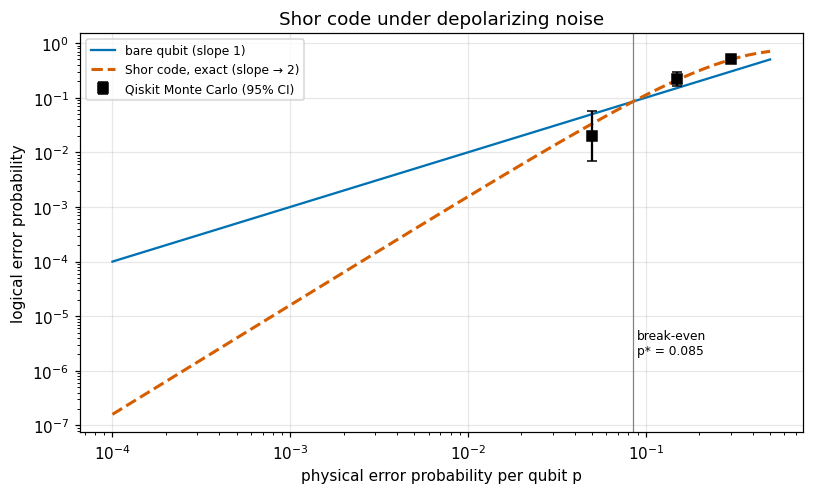

Figure: on log-log axes the bare-qubit line has slope 1 and the Shor curve has slope 2 at small p, so it lies far below; the curves cross at the break-even point p* ≈ 0.085. Black squares with error bars are Qiskit simulations and sit on the exact curve.


In [7]:
pL_f = sp.lambdify(p, pL, 'numpy')
ps = np.logspace(-4, -0.3, 60)
slopes = np.gradient(np.log(pL_f(ps)), np.log(ps))
print(f'local log-log slope at p = 1e-4: {slopes[0]:.3f};  at p = 0.01: {np.interp(-2, np.log10(ps), slopes):.3f}')

def wilson(k_, n_, z=1.96):
    ph = k_/n_; den = 1 + z*z/n_; c = (ph + z*z/(2*n_))/den; h = z*np.sqrt(ph*(1 - ph)/n_ + z*z/(4*n_*n_))/den
    return max(0.0, c - h), min(1.0, c + h)
mc_p, mc_rows = [0.05, 0.15, 0.3], []
for pv in mc_p:                                               # Qiskit Monte Carlo spot checks
    fails, n_mc = 0, 150
    for _ in range(n_mc):
        errs = {q: 'XYZ'[rng.integers(3)] for q in range(9) if rng.random() < pv}
        fails += state_fidelity(run_cycle(STATES['0'], errs), STATES['0']) < 0.5 or \
                 state_fidelity(run_cycle(STATES['+'], errs), STATES['+']) < 0.5
    mc_rows.append((pv, fails/n_mc, *wilson(fails, n_mc)))
print('note: the Monte Carlo counts a failure if |0> or |+> is ruined, i.e. any logical X, Y or Z error')
for pv, est, lo, hi in mc_rows:
    print(f'  p = {pv:4.2f}: Qiskit Monte Carlo {est:.3f}  [95% CI {lo:.3f}, {hi:.3f}]   exact {float(pL_f(pv)):.3f}')

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.loglog(ps, ps, '-', label='bare qubit (slope 1)')
ax.loglog(ps, pL_f(ps), '--', lw=2, label='Shor code, exact (slope → 2)')
ax.errorbar([r[0] for r in mc_rows], [r[1] for r in mc_rows],
            yerr=[[r[1] - r[2] for r in mc_rows], [r[3] - r[1] for r in mc_rows]], fmt='s', color='k', capsize=3,
            label='Qiskit Monte Carlo (95% CI)')
ax.axvline(float(p_star), color='gray', lw=0.8); ax.text(float(p_star)*1.05, 2e-6, f'break-even\np* = {float(p_star):.3f}', fontsize=8)
ax.set_xlabel('physical error probability per qubit p'); ax.set_ylabel('logical error probability'); ax.legend(fontsize=8)
ax.set_title('Shor code under depolarizing noise'); plt.tight_layout(); plt.show()
print('Figure: on log-log axes the bare-qubit line has slope 1 and the Shor curve has slope 2 at small p, so it '
      f'lies far below; the curves cross at the break-even point p* ≈ {float(p_star):.3f}. Black squares with error '
      'bars are Qiskit simulations and sit on the exact curve.')

---
## 7. Proofs in Lean 4

A Pauli operator on nine qubits is two 9-bit masks, $(x, z)$: bit $j$ of $x$ means an $X$ on qubit $j$, of $z$ a $Z$ (both means $Y$). Two Paulis **commute** exactly when the number of positions where one has $X$ and the other has $Z$ is even (the symplectic product). With that encoding, core Lean can check, by computation:
1. all eight stabilizers commute with each other;
2. the logical operators commute with every stabilizer and **anticommute** with each other;
3. every one of the 27 single-qubit errors anticommutes with at least one stabilizer, so it is **detected**;
4. the decoder model (written again in Lean) fails on **0** single errors and on exactly $N_2$ double errors, the same count SymPy used for the leading term.

In [8]:
N2 = Nk[2]
lean_src = f'''
-- Shor code facts, checked by the Lean kernel (core Lean 4, no Mathlib)
structure Pauli where
  x : Nat
  z : Nat

def popc (n : Nat) : Nat := (List.range 9).foldl (fun acc i => acc + (n >>> i) % 2) 0

-- symplectic product: Paulis commute iff it is even
def commutes (a b : Pauli) : Bool := popc ((a.x &&& b.z) ^^^ (a.z &&& b.x)) % 2 == 0

def zz (i j : Nat) : Pauli := ⟨0, (1 <<< i) ||| (1 <<< j)⟩
def stabilizers : List Pauli :=
  [zz 0 1, zz 1 2, zz 3 4, zz 4 5, zz 6 7, zz 7 8, ⟨0b000111111, 0⟩, ⟨0b111111000, 0⟩]
def Xbar : Pauli := ⟨0, 0b111111111⟩     -- Z on all nine qubits
def Zbar : Pauli := ⟨0b111111111, 0⟩     -- X on all nine qubits

theorem stabilizers_commute :
    stabilizers.all (fun a => stabilizers.all (fun b => commutes a b)) = true := by decide +kernel
theorem logicals_commute_with_stabilizers :
    stabilizers.all (fun s => commutes s Xbar && commutes s Zbar) = true := by decide +kernel
theorem logicals_anticommute : commutes Xbar Zbar = false := by decide +kernel

def singleErrors : List Pauli :=
  (List.range 9).flatMap (fun j => [⟨1 <<< j, 0⟩, ⟨1 <<< j, 1 <<< j⟩, ⟨0, 1 <<< j⟩])   -- X, Y, Z on qubit j
theorem every_single_error_detected :
    singleErrors.all (fun e => stabilizers.any (fun s => !commutes s e)) = true := by decide +kernel

-- the Pauli-frame decoder model from Section 5
def grp (n b : Nat) : Nat := popc ((n >>> (3 * b)) &&& 7)
def fails (e : Pauli) : Bool :=
  let zpar := (List.range 3).map (fun b => grp e.z b % 2)
  let resid := (List.range 3).map (fun b => if grp e.x b ≥ 2 then 1 else 0)
  (zpar.foldl (· + ·) 0 ≥ 2) || (resid.foldl (· + ·) 0 % 2 == 1)

def combine (a b : Pauli) : Pauli := ⟨a.x ^^^ b.x, a.z ^^^ b.z⟩
def onQubit (j : Nat) : List Pauli := [⟨1 <<< j, 0⟩, ⟨1 <<< j, 1 <<< j⟩, ⟨0, 1 <<< j⟩]
def doubleErrors : List Pauli :=
  (List.range 9).flatMap (fun i => (List.range 9).flatMap (fun j =>
    if i < j then (onQubit i).flatMap (fun a => (onQubit j).map (fun b => combine a b)) else []))

theorem no_single_error_fails : (singleErrors.filter fails).length = 0 := by decide +kernel
theorem double_error_count : doubleErrors.length = 324 := by decide +kernel
theorem failing_double_errors : (doubleErrors.filter fails).length = {N2} := by decide +kernel
'''
lean_file = pathlib.Path.cwd() / 'shor_code.lean'
lean_file.write_text(lean_src.strip() + '\n', encoding='utf-8')
print(lean_src.strip())
r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: {lean_src.count("theorem ")} theorems, exit code {r.returncode}')
print('✓ all verified by the Lean kernel' if r.returncode == 0 else (r.stdout + r.stderr))
print(f'(so the leading term N2 (p/3)^2 = {N2}/9 p^2 = {sp.Rational(N2, 9)} p^2 is backed by a Lean-checked count)')

-- Shor code facts, checked by the Lean kernel (core Lean 4, no Mathlib)
structure Pauli where
  x : Nat
  z : Nat

def popc (n : Nat) : Nat := (List.range 9).foldl (fun acc i => acc + (n >>> i) % 2) 0

-- symplectic product: Paulis commute iff it is even
def commutes (a b : Pauli) : Bool := popc ((a.x &&& b.z) ^^^ (a.z &&& b.x)) % 2 == 0

def zz (i j : Nat) : Pauli := ⟨0, (1 <<< i) ||| (1 <<< j)⟩
def stabilizers : List Pauli :=
  [zz 0 1, zz 1 2, zz 3 4, zz 4 5, zz 6 7, zz 7 8, ⟨0b000111111, 0⟩, ⟨0b111111000, 0⟩]
def Xbar : Pauli := ⟨0, 0b111111111⟩     -- Z on all nine qubits
def Zbar : Pauli := ⟨0b111111111, 0⟩     -- X on all nine qubits

theorem stabilizers_commute :
    stabilizers.all (fun a => stabilizers.all (fun b => commutes a b)) = true := by decide +kernel
theorem logicals_commute_with_stabilizers :
    stabilizers.all (fun s => commutes s Xbar && commutes s Zbar) = true := by decide +kernel
theorem logicals_anticommute : commutes Xbar Zbar = false := by decide +kernel

de


shor_code.lean: 7 theorems, exit code 0
✓ all verified by the Lean kernel
(so the leading term N2 (p/3)^2 = 144/9 p^2 = 16 p^2 is backed by a Lean-checked count)


---
## Summary

- **Codewords and checks (SymPy):** both codewords are fixed by all eight stabilizers; $\bar X = Z^{\otimes9}$ and $\bar Z = X^{\otimes9}$ act as logical operators.
- **Circuit (Qiskit):** all 27 single-qubit Pauli errors on all six test states are corrected with fidelity 1.
- **Exact logical error rate:** from all 262,144 error patterns; slope 2 at small $p$; a break-even point with a bare qubit.
- **Lean:** stabilizers commute, logicals anticommute, every single error is detected, and the decoder's failure counts match.

**Honest limits:** one correction cycle with perfect gates and ancillas (code-capacity noise). Noisy ancillas and repeated rounds are the next step, and they are why practical thresholds are near 1%.

## References

[1] P. W. Shor, "Scheme for reducing decoherence in quantum computer memory," *Phys. Rev. A*, vol. 52, no. 4, pp. R2493–R2496, 1995, doi: 10.1103/PhysRevA.52.R2493.

[2] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010, sec. 10.2.

[3] D. Gottesman, "Stabilizer codes and quantum error correction," Ph.D. dissertation, Caltech, Pasadena, CA, USA, 1997, arXiv: quant-ph/9705052.

*Reference details written from memory; verify before citing.*